In [10]:
#1
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, warnings
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
warnings.filterwarnings("ignore")

DATA_PATH = "delivery_time_dataset.csv"   # or '/content/drive/MyDrive/delivery_time_dataset.csv'
TARGET = "delivery_time_min"

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head(3))
df.info()

Shape: (6000, 28)


,order_id,order_date,order_time,day_of_week,is_weekend,season,is_public_holiday,is_festive_season,pickup_lat,pickup_lon,...,courier_rating,courier_experience_yrs,courier_deliveries_completed,vehicle_type,package_type,package_weight_kg,package_size,is_fragile,preparation_time_min,delivery_time_min
0,1,2025-08-13,18:56,Wednesday,0,Monsoon,0,0,25.44414,81.85275,...,4.6,17.2,8914,Scooter,Fragile,6.98,Large,1,1.6,23.3
1,2,2025-01-18,18:48,Saturday,1,Winter,0,0,25.40380,81.84440,...,4.7,5.2,1769,Cycle,Food,NaN,Medium,0,12.2,67.8
2,3,2025-11-01,08:49,Saturday,1,Autumn,0,1,25.45751,81.87192,...,3.8,9.0,5263,Scooter,Grocery,2.98,Medium,0,4.6,48.7


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   order_id                      6000 non-null   int64  
 1   order_date                    6000 non-null   object 
 2   order_time                    6000 non-null   object 
 3   day_of_week                   6000 non-null   object 
 4   is_weekend                    6000 non-null   int64  
 5   season                        6000 non-null   object 
 6   is_public_holiday             6000 non-null   int64  
 7   is_festive_season             6000 non-null   int64  
 8   pickup_lat                    6000 non-null   float64
 9   pickup_lon                    6000 non-null   float64
 10  drop_lat                      6000 non-null   float64
 11  drop_lon                      6000 non-null   float64
 12  route_distance_km             6000 non-null   float64
 13  zon

In [11]:
#2
required = ["pickup_lat", "pickup_lon", "drop_lat", "drop_lon", "traffic_level", TARGET]
missing_cols = [c for c in required if c not in df.columns]
assert not missing_cols, f"Missing required columns: {missing_cols}"

print("Duplicate rows:", df.duplicated().sum())
miss = df.isna().sum()
print("\nMissing values:\n", miss[miss > 0])
display(df.describe().T)

Duplicate rows: 0

Missing values:
 zone_type             54
traffic_level         42
weather              125
courier_rating       186
package_weight_kg    182
package_size         123
dtype: int64


,count,mean,std,min,25%,50%,75%,max
order_id,6000.0,3000.500000,1732.195139,1.00000,1500.750000,3000.500000,4500.250000,6000.000000
is_weekend,6000.0,0.282333,0.450172,0.00000,0.000000,0.000000,1.000000,1.000000
is_public_holiday,6000.0,0.022000,0.146696,0.00000,0.000000,0.000000,0.000000,1.000000
is_festive_season,6000.0,0.152833,0.359857,0.00000,0.000000,0.000000,0.000000,1.000000
pickup_lat,6000.0,25.371165,1.270607,0.00000,25.414380,25.435185,25.454210,25.538620
pickup_lon,6000.0,81.640930,4.087611,0.00000,81.825437,81.844680,81.865673,81.970540
drop_lat,6000.0,25.435492,0.050074,25.22679,25.401200,25.434820,25.469400,25.606780
drop_lon,6000.0,81.846876,0.050111,81.67449,81.813128,81.846945,81.880525,82.031460
route_distance_km,6000.0,6.895225,3.607635,0.20000,4.140000,6.450000,9.180000,22.940000
num_stops,6000.0,1.595000,0.848191,1.00000,1.000000,1.000000,2.000000,4.000000


In [12]:
#3
n0 = len(df)

# 1. Fix inconsistent labels ("sunny ", "RAINY" -> "Sunny", "Rainy")
text_cols = df.select_dtypes(include=["object", "string"]).columns.difference(
    ["order_date", "order_time"])
for c in text_cols:
    df[c] = df[c].astype("string").str.strip().str.title()
    df[c] = df[c].astype(object).where(df[c].notna(), np.nan)

# 2. Remove duplicates
df = df.drop_duplicates(subset="order_id") if "order_id" in df.columns else df.drop_duplicates()

# 3. Remove impossible coordinates
coords_ok = (
    df.pickup_lat.between(-90, 90) & df.drop_lat.between(-90, 90) &
    df.pickup_lon.between(-180, 180) & df.drop_lon.between(-180, 180) &
    (df.pickup_lat != 0) & (df.pickup_lon != 0) &
    (df.drop_lat != 0) & (df.drop_lon != 0))
print("Bad coordinates removed:", (~coords_ok).sum())
df = df[coords_ok]

# 4. Impossible values become missing (imputed later)
for c in ["package_weight_kg", "courier_age", "courier_rating"]:
    if c in df.columns:
        df.loc[df[c] <= 0, c] = np.nan
df = df[df[TARGET] > 0]

# 5. Extreme target values: drop beyond Q3 + 3*IQR
q1, q3 = df[TARGET].quantile([0.25, 0.75])
upper = q3 + 3 * (q3 - q1)
print(f"Target upper fence: {upper:.1f} min | rows above: {(df[TARGET] > upper).sum()}")
df = df[df[TARGET] <= upper]

print(f"\nRows before: {n0} | after: {len(df)} | removed: {n0 - len(df)}")
print("Target skew:", round(df[TARGET].skew(), 2))
print("Weather labels:", df["weather"].unique())

Bad coordinates removed: 15
Target upper fence: 106.3 min | rows above: 22

Rows before: 6000 | after: 5963 | removed: 37
Target skew: 0.9
Weather labels: ['Cloudy' 'Stormy' 'Sunny' 'Rainy' 'Foggy' nan]


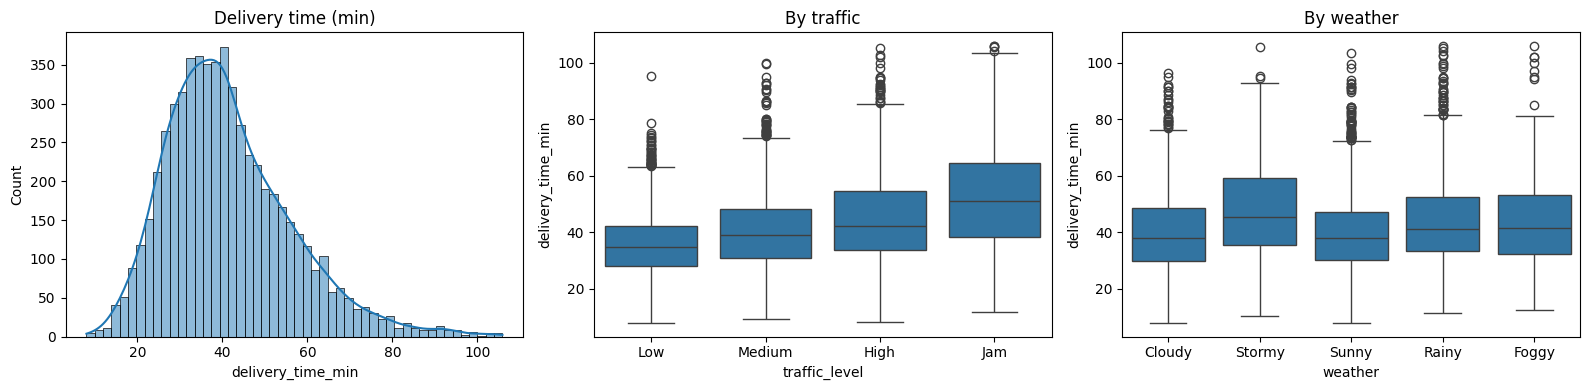

In [13]:
#4
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df[TARGET], bins=50, kde=True, ax=ax[0]).set_title("Delivery time (min)")
sns.boxplot(data=df, x="traffic_level", y=TARGET,
            order=["Low", "Medium", "High", "Jam"], ax=ax[1]).set_title("By traffic")
sns.boxplot(data=df, x="weather", y=TARGET, ax=ax[2]).set_title("By weather")
plt.tight_layout(); plt.show()

In [14]:
#5
df["order_dt"] = pd.to_datetime(df["order_date"] + " " + df["order_time"])
df = df.sort_values("order_dt").reset_index(drop=True)
print(df.order_dt.min(), "to", df.order_dt.max())

2025-01-01 09:40:00 to 2025-12-31 23:52:00


In [15]:
#6
USE_THREE_WAY = False   # three-way experiments; switch on later only if CV improves

def haversine(a, b, c, d):
    a, b, c, d = map(np.radians, [a, b, c, d])
    x = np.sin((c - a) / 2) ** 2 + np.cos(a) * np.cos(c) * np.sin((d - b) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(x))

def build_features(d):
    d = d.copy()
    # Tier 1: route, traffic, courier, package
    d["distance_km"] = haversine(d.pickup_lat, d.pickup_lon, d.drop_lat, d.drop_lon)
    d["distance_bucket"] = pd.cut(d.distance_km, [0, 2, 5, 10, 1e3],
                                  labels=["short", "medium", "long", "very_long"]).astype(str)
    d["traffic_score"] = d.traffic_level.map({"Low": 0, "Medium": 1, "High": 2, "Jam": 3}).astype(float)
    d["stops_per_km"] = d.num_stops / d.distance_km.clip(lower=0.1)
    d["dist_plus_stops"] = d.distance_km + d.num_stops
    d["exp_band"] = pd.cut(d.courier_experience_yrs, [-1, 2, 5, 10, 100],
                           labels=["novice", "mid", "senior", "expert"]).astype(str)
    d["handling_score"] = d.package_type.map(
        {"Documents": 1, "Food": 2, "Grocery": 2, "Electronics": 3, "Fragile": 4}).astype(float) + d.is_fragile
    d["weight_x_dist"] = d.package_weight_kg * d.distance_km
    # Tier 2: weather, time, vehicle
    d["bad_weather"] = d.weather.isin(["Rainy", "Stormy", "Foggy"]).astype(float).where(d.weather.notna())
    d["weather_x_traffic"] = d.bad_weather * d.traffic_score
    d["hour"] = d.order_dt.dt.hour
    d["rush_hour"] = (d.hour.between(12, 14) | d.hour.between(19, 21)).astype(int)
    d["meal_period"] = pd.cut(d.hour, [-1, 10, 15, 18, 24],
                              labels=["morning", "lunch", "evening", "dinner"]).astype(str)
    d["vehicle_x_dist"] = d.vehicle_type.map(
        {"Bike": 1, "Scooter": 1.05, "Car": 1.2, "Cycle": 1.6}).astype(float) * d.distance_km
    # Tier 3: pairwise interactions
    d["dist_x_traffic"] = d.distance_km * d.traffic_score
    d["pkg_x_traffic"] = d.handling_score * d.traffic_score
    d["pkg_x_route"] = d.handling_score * d.distance_km
    d["dist_x_lowrating"] = d.distance_km * (5 - d.courier_rating)
    d["courier_x_traffic"] = (5 - d.courier_rating) * d.traffic_score
    d["courier_x_pkg"] = (5 - d.courier_rating) * d.handling_score
    d["zone_x_traffic"] = (d.zone_type == "Commercial").astype(float) * d.traffic_score
    if USE_THREE_WAY:
        d["route_traffic_courier"] = d.distance_km * d.traffic_score * (5 - d.courier_rating)
        d["route_courier_pkg"] = d.distance_km * (5 - d.courier_rating) * d.handling_score
    return d

fe = build_features(df)
print(fe.shape)

(5963, 50)


Numeric (29): ['is_weekend', 'is_public_holiday', 'is_festive_season', 'route_distance_km', 'num_stops', 'courier_age', 'courier_rating', 'courier_experience_yrs', 'courier_deliveries_completed', 'package_weight_kg', 'is_fragile', 'preparation_time_min', 'distance_km', 'traffic_score', 'stops_per_km', 'dist_plus_stops', 'handling_score', 'weight_x_dist', 'bad_weather', 'weather_x_traffic', 'rush_hour', 'vehicle_x_dist', 'dist_x_traffic', 'pkg_x_traffic', 'pkg_x_route', 'dist_x_lowrating', 'courier_x_traffic', 'courier_x_pkg', 'zone_x_traffic']
Categorical (10): ['day_of_week', 'zone_type', 'traffic_level', 'weather', 'vehicle_type', 'package_type', 'package_size', 'distance_bucket', 'exp_band', 'meal_period']
train: 4174 rows | 2025-01-01 to 2025-09-13
val: 894 rows | 2025-09-13 to 2025-11-04
test: 895 rows | 2025-11-04 to 2025-12-31

Top correlations with target:
 vehicle_x_dist       0.824
dist_plus_stops      0.790
distance_km          0.786
route_distance_km    0.785
dist_x_traffic

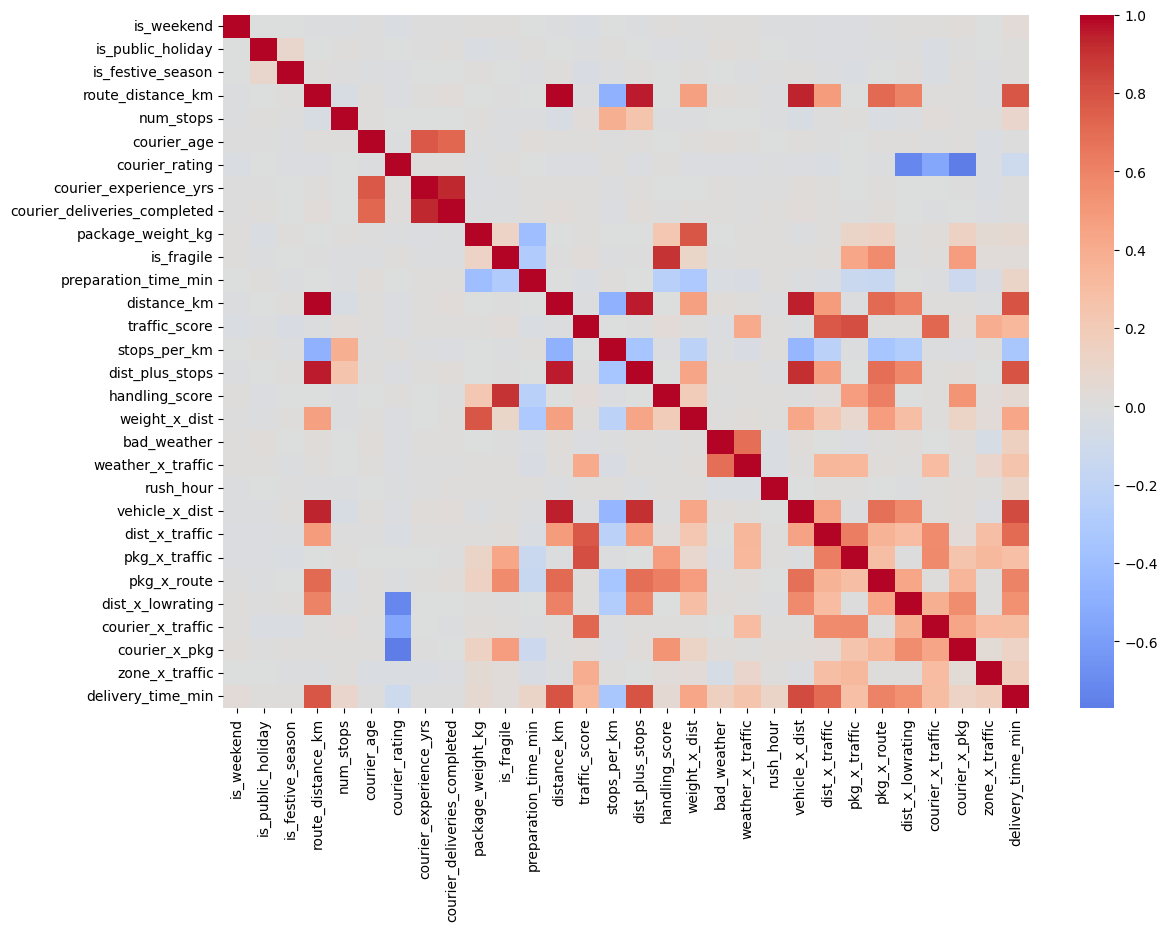

In [16]:
#7
# month and season are excluded: a time-based split means training never sees Oct to Dec
drop_cols = [TARGET, "order_id", "order_date", "order_time", "order_dt",
             "pickup_lat", "pickup_lon", "drop_lat", "drop_lon", "hour",
             "season", "month"]
features = [c for c in fe.columns if c not in drop_cols]
cat_cols = [c for c in features if fe[c].dtype == "object"]
num_cols = [c for c in features if c not in cat_cols]
print("Numeric (%d):" % len(num_cols), num_cols)
print("Categorical (%d):" % len(cat_cols), cat_cols)

n = len(fe); i1, i2 = int(0.70 * n), int(0.85 * n)      # fe is already sorted by time
tr, va, te = fe.iloc[:i1], fe.iloc[i1:i2], fe.iloc[i2:]
for name, part in [("train", tr), ("val", va), ("test", te)]:
    print(f"{name}: {len(part)} rows | {part.order_dt.min().date()} to {part.order_dt.max().date()}")

# Correlations (train only)
corr = tr[num_cols + [TARGET]].corr()
print("\nTop correlations with target:\n",
      corr[TARGET].drop(TARGET).abs().sort_values(ascending=False).head(12).round(3))
cm = corr.drop(index=TARGET, columns=TARGET).abs()
pairs = [(a, b, round(cm.loc[a, b], 2)) for i, a in enumerate(cm.index)
         for b in cm.columns[i + 1:] if cm.loc[a, b] > 0.9]
print("\nPairs above 0.9:", pairs)
plt.figure(figsize=(13, 9)); sns.heatmap(corr, cmap="coolwarm", center=0); plt.show()

In [17]:
#8
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

X_train, y_train = tr[features], tr[TARGET]
X_val,   y_val   = va[features], va[TARGET]
X_test,  y_test  = te[features], te[TARGET]

Xt = preprocessor.fit_transform(X_train)
print("Train matrix:", Xt.shape, "| val:", preprocessor.transform(X_val).shape,
      "| test:", preprocessor.transform(X_test).shape)
print("NaN left in train:", np.isnan(Xt.toarray() if hasattr(Xt, "toarray") else Xt).any())

Train matrix: (4174, 84) | val: (894, 84) | test: (895, 84)
NaN left in train: False


In [18]:
#9
from sklearn.base import clone

protected = {"distance_km", "traffic_score", "courier_rating", "package_weight_kg", "handling_score"}
tcorr = corr[TARGET].drop(TARGET).abs()
to_drop = set()
for a, b, v in pairs:
    if a in to_drop or b in to_drop: continue
    if a in protected and b in protected: continue
    if a in protected: to_drop.add(b)
    elif b in protected: to_drop.add(a)
    else: to_drop.add(a if tcorr[a] < tcorr[b] else b)
print("Dropped as redundant:", sorted(to_drop))

num_cols = [c for c in num_cols if c not in to_drop]
features = num_cols + cat_cols
X_train, y_train = tr[features], tr[TARGET]
X_val,   y_val   = va[features], va[TARGET]
X_test,  y_test  = te[features], te[TARGET]

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])
print(len(num_cols), "numeric,", len(cat_cols), "categorical features kept")

Dropped as redundant: ['courier_experience_yrs', 'dist_plus_stops', 'route_distance_km', 'vehicle_x_dist']
25 numeric, 10 categorical features kept


In [46]:
import shutil, os
shutil.rmtree("ckpt", ignore_errors=True)
os.makedirs("ckpt", exist_ok=True)

In [47]:
#10
!pip -q install xgboost shap
import json, joblib, time, os
from sklearn.model_selection import ParameterSampler, TimeSeriesSplit, cross_val_score, cross_validate   # CHANGED
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
SEED = 42
N_ITER, TUNE_FRAC, CV_FOLDS = 8, 0.6, 5        # CHANGED: final-run settings

CKPT = "ckpt"          # use '/content/drive/MyDrive/ckpt' (after mounting Drive) so it survives disconnects
os.makedirs(CKPT, exist_ok=True)
TRIALS_FILE = f"{CKPT}/trials.json"
trials_db = json.load(open(TRIALS_FILE)) if os.path.exists(TRIALS_FILE) else {}
tojson = lambda o: o.item() if hasattr(o, "item") else str(o)

def make_pipe(reg):   # log-transform the target (skew 0.9); predictions come back in minutes
    return Pipeline([("prep", clone(preprocessor)),
                     ("model", TransformedTargetRegressor(regressor=reg, func=np.log1p, inverse_func=np.expm1))])

idx = X_train.sample(frac=TUNE_FRAC, random_state=SEED).sort_index().index      # CHANGED: keep time order
X_tune, y_tune = X_train.loc[idx], y_train.loc[idx]
kf = TimeSeriesSplit(n_splits=CV_FOLDS)                                          # CHANGED: time-ordered folds

spaces = {
  "Linear Regression": (make_pipe(LinearRegression()), None),
  "Random Forest": (make_pipe(RandomForestRegressor(random_state=SEED, n_jobs=-1)),
      {"model__regressor__n_estimators": [80, 120], "model__regressor__max_depth": [8, 12],
       "model__regressor__min_samples_leaf": [3, 8]}),
  "XGBoost": (make_pipe(XGBRegressor(random_state=SEED, tree_method="hist", n_jobs=-1)),
      {"model__regressor__n_estimators": [150, 300], "model__regressor__learning_rate": [0.05, 0.1],
       "model__regressor__max_depth": [3, 5], "model__regressor__subsample": [0.8, 1],
       "model__regressor__colsample_bytree": [0.8, 1]})}

# Overall progress: every tuning trial + one "final fit and CV" step per model
total = sum(N_ITER for _, (_, sp) in spaces.items() if sp) + len(spaces)
done, T0 = 0, time.time()
def progress(msg):
    print(f"[{done}/{total} steps | {time.time()-T0:.0f}s elapsed] {msg}")

fitted, cv_rows = {}, []
for name, (pipe, space) in spaces.items():
    mfile, rfile = f"{CKPT}/{name.replace(' ','_')}.pkl", f"{CKPT}/{name.replace(' ','_')}_cv.json"
    if os.path.exists(mfile) and os.path.exists(rfile):                 # model finished in an earlier run
        fitted[name] = joblib.load(mfile); cv_rows.append(json.load(open(rfile)))
        done += (N_ITER if space else 0) + 1; progress(f"{name}: loaded from checkpoint"); continue

    best = pipe
    if space:
        sampled = list(ParameterSampler(space, n_iter=N_ITER, random_state=SEED))
        results = trials_db.setdefault(name, [])
        seen = {json.dumps(r["params"], sort_keys=True, default=tojson): r["rmse"] for r in results}
        for i, params in enumerate(sampled, 1):
            key = json.dumps(params, sort_keys=True, default=tojson)
            if key in seen:
                done += 1; progress(f"{name} trial {i}/{N_ITER}: resumed, RMSE {seen[key]:.3f}"); continue
            t0 = time.time()
            rmse = -cross_val_score(clone(pipe).set_params(**params), X_tune, y_tune, cv=kf,
                                    scoring="neg_root_mean_squared_error", n_jobs=1).mean()
            results.append({"params": json.loads(key), "rmse": float(rmse)})
            json.dump(trials_db, open(TRIALS_FILE, "w"), default=tojson)      # checkpoint after every trial
            done += 1; progress(f"{name} trial {i}/{N_ITER}: RMSE {rmse:.3f} ({time.time()-t0:.0f}s)")
        top = min(trials_db[name], key=lambda r: r["rmse"])
        best = clone(pipe).set_params(**top["params"])
        print("   best params:", {k.split("__")[-1]: v for k, v in top["params"].items()})

    t0 = time.time()
    fitted[name] = clone(best).fit(X_train, y_train)                  # refit on the full training set
    cv = cross_validate(clone(best), X_train, y_train, cv=kf, n_jobs=1,
                        scoring=["neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"])
    row = {"model": name,
        "CV RMSE": f"{-cv['test_neg_root_mean_squared_error'].mean():.2f} +/- {cv['test_neg_root_mean_squared_error'].std():.2f}",
        "CV MAE": f"{-cv['test_neg_mean_absolute_error'].mean():.2f} +/- {cv['test_neg_mean_absolute_error'].std():.2f}",
        "CV R2": f"{cv['test_r2'].mean():.3f} +/- {cv['test_r2'].std():.3f}"}
    cv_rows.append(row)
    joblib.dump(fitted[name], mfile); json.dump(row, open(rfile, "w"))  # checkpoint after every finished model
    done += 1; progress(f"{name}: final fit + CV done ({time.time()-t0:.0f}s), checkpoint saved")

display(pd.DataFrame(cv_rows).set_index("model"))

[1/19 steps | 0s elapsed] Linear Regression: final fit + CV done (0s), checkpoint saved
[2/19 steps | 6s elapsed] Random Forest trial 1/8: RMSE 6.207 (6s)
[3/19 steps | 13s elapsed] Random Forest trial 2/8: RMSE 6.190 (7s)
[4/19 steps | 16s elapsed] Random Forest trial 3/8: RMSE 6.501 (3s)
[5/19 steps | 20s elapsed] Random Forest trial 4/8: RMSE 6.490 (5s)
[6/19 steps | 24s elapsed] Random Forest trial 5/8: RMSE 6.066 (4s)
[7/19 steps | 31s elapsed] Random Forest trial 6/8: RMSE 6.049 (6s)
[8/19 steps | 33s elapsed] Random Forest trial 7/8: RMSE 6.434 (3s)
[9/19 steps | 38s elapsed] Random Forest trial 8/8: RMSE 6.426 (4s)
   best params: {'max_depth': 12, 'min_samples_leaf': 3, 'n_estimators': 120}
[10/19 steps | 51s elapsed] Random Forest: final fit + CV done (14s), checkpoint saved
[11/19 steps | 53s elapsed] XGBoost trial 1/8: RMSE 5.087 (1s)
[12/19 steps | 55s elapsed] XGBoost trial 2/8: RMSE 5.025 (3s)
[13/19 steps | 56s elapsed] XGBoost trial 3/8: RMSE 4.530 (1s)
[14/19 steps | 

,CV RMSE,CV MAE,CV R2
model,,,
Linear Regression,4.41 +/- 0.47,3.23 +/- 0.18,0.912 +/- 0.021
Random Forest,5.57 +/- 0.62,4.16 +/- 0.26,0.860 +/- 0.033
XGBoost,4.26 +/- 0.53,3.19 +/- 0.21,0.918 +/- 0.022


In [21]:
#11
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

SEED = 42

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("ANN libraries imported successfully!")


TensorFlow version: 2.21.0
ANN libraries imported successfully!


In [23]:
#12
from sklearn.base import clone

# Create an independent copy of the final preprocessor
ann_preprocessor = clone(preprocessor)

# Fit ONLY on training data
X_train_ann = ann_preprocessor.fit_transform(X_train)

# Transform validation and test data
X_val_ann = ann_preprocessor.transform(X_val)
X_test_ann = ann_preprocessor.transform(X_test)

print("ANN preprocessing completed!")

print("Train:", X_train_ann.shape)
print("Validation:", X_val_ann.shape)
print("Test:", X_test_ann.shape)


ANN preprocessing completed!
Train: (4174, 80)
Validation: (894, 80)
Test: (895, 80)


In [24]:
#13
def to_dense(X):
    if hasattr(X, "toarray"):
        X = X.toarray()

    return np.asarray(X, dtype=np.float32)


X_train_ann = to_dense(X_train_ann)
X_val_ann = to_dense(X_val_ann)
X_test_ann = to_dense(X_test_ann)

print("Training shape:", X_train_ann.shape)
print("Validation shape:", X_val_ann.shape)
print("Testing shape:", X_test_ann.shape)


Training shape: (4174, 80)
Validation shape: (894, 80)
Testing shape: (895, 80)


In [25]:
#14
y_train_ann = np.asarray(y_train, dtype=np.float32).reshape(-1)
y_val_ann = np.asarray(y_val, dtype=np.float32).reshape(-1)
y_test_ann = np.asarray(y_test, dtype=np.float32).reshape(-1)

# Check that log1p is valid
assert np.all(y_train_ann > -1)
assert np.all(y_val_ann > -1)
assert np.all(y_test_ann > -1)

# Apply log transformation
y_train_log = np.log1p(y_train_ann)
y_val_log = np.log1p(y_val_ann)

print("Target transformation completed!")
print("Original target mean:", y_train_ann.mean())
print("Log target mean:", y_train_log.mean())


Target transformation completed!
Original target mean: 41.343643
Log target mean: 3.684879


In [26]:
#15
assert X_train_ann.shape[1] == X_val_ann.shape[1]
assert X_train_ann.shape[1] == X_test_ann.shape[1]

assert len(X_train_ann) == len(y_train_log)
assert len(X_val_ann) == len(y_val_log)
assert len(X_test_ann) == len(y_test_ann)

assert np.isfinite(X_train_ann).all()
assert np.isfinite(X_val_ann).all()
assert np.isfinite(X_test_ann).all()

assert np.isfinite(y_train_log).all()
assert np.isfinite(y_val_log).all()

print("All ANN validation checks passed!")


All ANN validation checks passed!


In [27]:
#16
os.makedirs(CKPT, exist_ok=True)

ANN_CHECKPOINT = f"{CKPT}/best_ann.keras"
ANN_FINAL = f"{CKPT}/ann_model.keras"

print("ANN checkpoint directory:", CKPT)


ANN checkpoint directory: ckpt


In [28]:
#17
model = Sequential([

    tf.keras.Input(shape=(X_train_ann.shape[1],)),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.25),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.25),

    Dense(32, activation="relu"),
    Dropout(0.20),

    Dense(1, activation="linear")

])

print("ANN architecture created!")


ANN architecture created!


In [41]:
#18
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.Huber(delta=0.15),
    metrics=["mae"]
)

print("ANN compiled successfully!")


ANN compiled successfully!


In [42]:
#19
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        10,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,505 (84.00 KB)

 Trainable params: 21,121 (82.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [31]:
#20
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=12,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

checkpoint = ModelCheckpoint(
    filepath=ANN_CHECKPOINT,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

callbacks = [
    early_stop,
    reduce_lr,
    checkpoint
]

print("Callbacks configured!")


Callbacks configured!


In [32]:
#21
history = model.fit(

    X_train_ann,
    y_train_log,

    validation_data=(
        X_val_ann,
        y_val_log
    ),

    epochs=150,
    batch_size=32,

    callbacks=callbacks,

    verbose=1

)


Epoch 1/150
108/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.6319 - mae: 2.0893
Epoch 1: val_loss improved from None to 0.98967, saving model to ckpt/best_ann.keras

Epoch 1: finished saving model to ckpt/best_ann.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 1.0389 - mae: 1.4635 - val_loss: 0.9897 - val_mae: 1.4805 - learning_rate: 0.0010
Epoch 2/150
109/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5531 - mae: 0.9442
Epoch 2: val_loss improved from 0.98967 to 0.38874, saving model to ckpt/best_ann.keras

Epoch 2: finished saving model to ckpt/best_ann.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5082 - mae: 0.8955 - val_loss: 0.3887 - val_mae: 0.8128 - learning_rate: 0.0010
Epoch 3/150
111/131 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4234 - mae: 0.7901
Epoch 3: val_loss improved from 0.38874 to 0.21421, saving model to ckpt/best_ann.keras

Epoch 3: finished saving model to ckpt/best_ann.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3955 - mae: 0.7

In [33]:
#22
model = load_model(ANN_CHECKPOINT)

print("Best ANN checkpoint loaded!")


Best ANN checkpoint loaded!


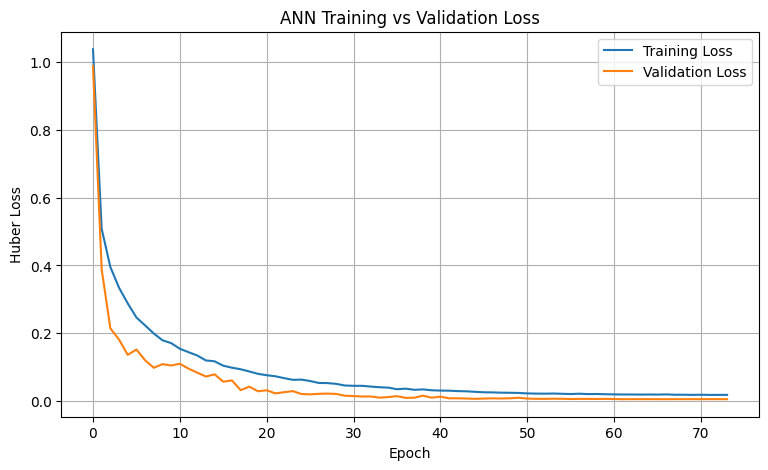

In [34]:

plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Huber Loss")
plt.title("ANN Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.show()


In [35]:
#23
y_pred_log = model.predict(
    X_test_ann,
    verbose=0
).flatten()

# Convert predictions back into minutes
y_pred_ann = np.expm1(y_pred_log)

print("Predictions generated!")

display(pd.DataFrame({
    "Actual Delivery Time": y_test_ann[:10],
    "Predicted Delivery Time": y_pred_ann[:10]
}))


Predictions generated!


,Actual Delivery Time,Predicted Delivery Time
0,38.200001,36.763531
1,56.799999,68.424980
2,27.200001,29.532074
3,66.199997,62.772743
4,37.900002,36.796154
5,44.500000,45.348251
6,46.599998,45.090073
7,29.400000,26.732571
8,18.299999,19.891291
9,33.900002,33.406906


In [36]:
#24
ann_rmse = np.sqrt(
    mean_squared_error(y_test_ann, y_pred_ann)
)

ann_mae = mean_absolute_error(
    y_test_ann,
    y_pred_ann
)

ann_r2 = r2_score(
    y_test_ann,
    y_pred_ann
)

print("========== ANN TEST RESULTS ==========")

print(f"RMSE: {ann_rmse:.4f}")
print(f"MAE : {ann_mae:.4f}")
print(f"R2  : {ann_r2:.4f}")


========== ANN TEST RESULTS ==========
RMSE: 3.7019
MAE : 2.8456
R2  : 0.9343


In [37]:
#25
model.save(ANN_FINAL)

joblib.dump(
    ann_preprocessor,
    f"{CKPT}/ann_preprocessor.pkl"
)

print("ANN model saved!")
print("ANN preprocessing pipeline saved!")


ANN model saved!
ANN preprocessing pipeline saved!


In [38]:
#26
ml_test_results = []

for name, model_ml in fitted.items():

    pred = model_ml.predict(X_test)

    rmse = np.sqrt(
        mean_squared_error(y_test, pred)
    )

    mae = mean_absolute_error(y_test, pred)

    r2 = r2_score(y_test, pred)

    ml_test_results.append({
        "Model": name,
        "Test RMSE": rmse,
        "Test MAE": mae,
        "Test R2": r2
    })

ml_test_df = pd.DataFrame(ml_test_results)

display(
    ml_test_df.sort_values("Test RMSE")
)


,Model,Test RMSE,Test MAE,Test R2
2,XGBoost,3.562595,2.830802,0.939145
0,Linear Regression,4.017796,3.042790,0.922600
1,Random Forest,4.563416,3.602078,0.900151


In [48]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone

def build_ann(input_dim, y_mean):
    m = Sequential([
        tf.keras.Input(shape=(input_dim,)),
        Dense(128, activation="relu"), BatchNormalization(), Dropout(0.25),
        Dense(64, activation="relu"),  BatchNormalization(), Dropout(0.25),
        Dense(32, activation="relu"),  Dropout(0.20),
        Dense(1, bias_initializer=tf.keras.initializers.Constant(float(y_mean)))])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss=tf.keras.losses.Huber(delta=0.15), metrics=["mae"])
    return m

tscv = TimeSeriesSplit(n_splits=5)
ann_cv = {"rmse": [], "mae": [], "r2": []}

for fold, (tr_i, va_i) in enumerate(tscv.split(X_train), 1):
    Xf_tr, Xf_va = X_train.iloc[tr_i], X_train.iloc[va_i]
    yf_tr, yf_va = y_train.iloc[tr_i].values, y_train.iloc[va_i].values

    prep = clone(preprocessor)                       # fit on this fold's train part only
    A_tr = to_dense(prep.fit_transform(Xf_tr))
    A_va = to_dense(prep.transform(Xf_va))

    # inner chronological validation split for early stopping (last 15% of fold-train)
    k = int(0.85 * len(A_tr))
    y_in_log = np.log1p(yf_tr[:k])
    tf.keras.utils.set_random_seed(SEED)
    m = build_ann(A_tr.shape[1], y_in_log.mean())    # bias starts at the mean log target
    m.fit(A_tr[:k], y_in_log,
          validation_data=(A_tr[k:], np.log1p(yf_tr[k:])),
          epochs=150, batch_size=32, verbose=0,
          callbacks=[EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True),
                     ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6)])

    p = np.expm1(m.predict(A_va, verbose=0).flatten())
    ann_cv["rmse"].append(np.sqrt(mean_squared_error(yf_va, p)))
    ann_cv["mae"].append(mean_absolute_error(yf_va, p))
    ann_cv["r2"].append(r2_score(yf_va, p))
    print(f"fold {fold}: train {len(tr_i)} rows | RMSE {ann_cv['rmse'][-1]:.2f} | "
          f"MAE {ann_cv['mae'][-1]:.2f} | R2 {ann_cv['r2'][-1]:.3f}")

ann_cv_row = {"model": "ANN",
    "CV RMSE": f"{np.mean(ann_cv['rmse']):.2f} +/- {np.std(ann_cv['rmse']):.2f}",
    "CV MAE":  f"{np.mean(ann_cv['mae']):.2f} +/- {np.std(ann_cv['mae']):.2f}",
    "CV R2":   f"{np.mean(ann_cv['r2']):.3f} +/- {np.std(ann_cv['r2']):.3f}"}
display(pd.DataFrame(cv_rows + [ann_cv_row]).set_index("model"))

fold 1: train 699 rows | RMSE 6.93 | MAE 4.64 | R2 0.780
fold 2: train 1394 rows | RMSE 4.70 | MAE 3.50 | R2 0.907
fold 3: train 2089 rows | RMSE 3.77 | MAE 2.92 | R2 0.932
fold 4: train 2784 rows | RMSE 4.41 | MAE 3.46 | R2 0.914
fold 5: train 3479 rows | RMSE 4.32 | MAE 3.36 | R2 0.920


,CV RMSE,CV MAE,CV R2
model,,,
Linear Regression,4.41 +/- 0.47,3.23 +/- 0.18,0.912 +/- 0.021
Random Forest,5.57 +/- 0.62,4.16 +/- 0.26,0.860 +/- 0.033
XGBoost,4.26 +/- 0.53,3.19 +/- 0.21,0.918 +/- 0.022
ANN,4.83 +/- 1.09,3.58 +/- 0.57,0.890 +/- 0.056


In [49]:
#27
ann_result = pd.DataFrame([{
    "Model": "ANN",
    "Test RMSE": ann_rmse,
    "Test MAE": ann_mae,
    "Test R2": ann_r2
}])

comparison_df = pd.concat(
    [ml_test_df, ann_result],
    ignore_index=True
)

comparison_df = comparison_df.sort_values(
    "Test RMSE"
).reset_index(drop=True)

display(
    comparison_df.style.format({
        "Test RMSE": "{:.4f}",
        "Test MAE": "{:.4f}",
        "Test R2": "{:.4f}"
    })
)


,Model,Test RMSE,Test MAE,Test R2
0,XGBoost,3.5626,2.8308,0.9391
1,ANN,3.7019,2.8456,0.9343
2,Linear Regression,4.0178,3.0428,0.9226
3,Random Forest,4.5634,3.6021,0.9002


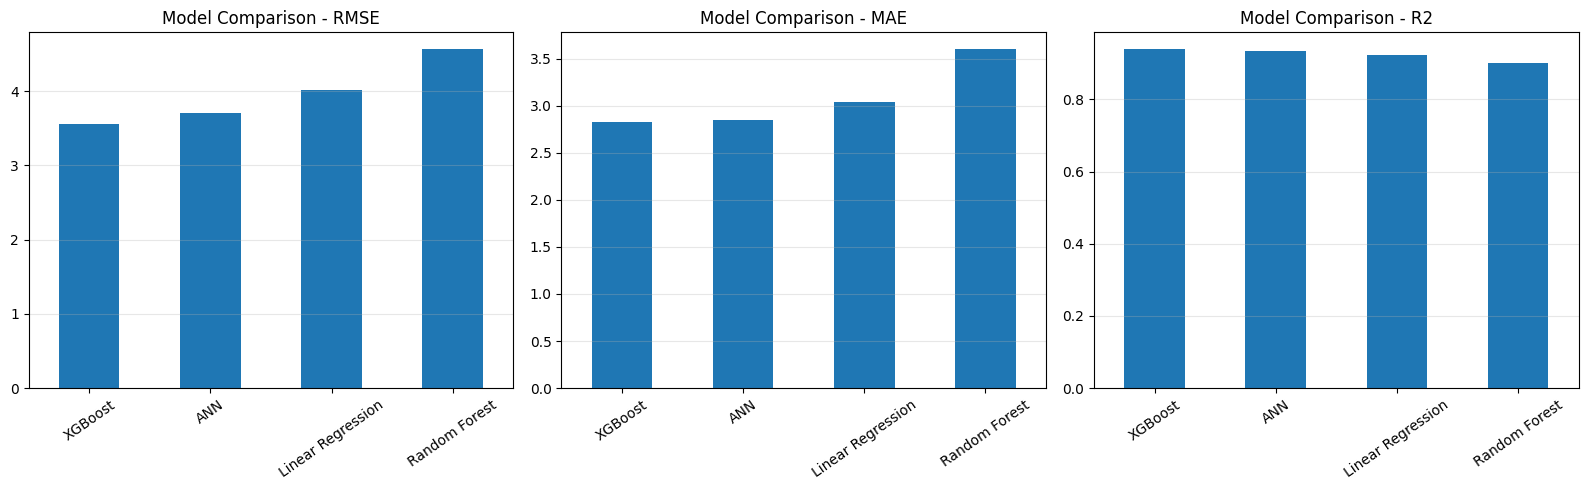

In [40]:
#27
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = [
    ("Test RMSE", "RMSE"),
    ("Test MAE", "MAE"),
    ("Test R2", "R2")
]

for ax, (column, title) in zip(axes, metrics):

    comparison_df.plot(
        x="Model",
        y=column,
        kind="bar",
        ax=ax,
        legend=False
    )

    ax.set_title(f"Model Comparison - {title}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [50]:
import json, joblib, os
os.makedirs("deploy", exist_ok=True)

best_ml      = ml_test_df.sort_values("Test RMSE").iloc[0]["Model"]
best_overall = comparison_df.iloc[0]["Model"]          # comparison_df is sorted by Test RMSE

cat_inputs = ["zone_type", "traffic_level", "weather", "vehicle_type", "package_type", "package_size"]
num_inputs = ["num_stops", "courier_age", "courier_rating", "courier_experience_yrs",
              "courier_deliveries_completed", "package_weight_kg", "preparation_time_min",
              "pickup_lat", "pickup_lon", "drop_lat", "drop_lon"]

meta = {
    "features": features,
    "ml_name": best_ml,
    "best_overall_name": best_overall,
    "best_overall": "DL" if best_overall == "ANN" else "ML",
    "options":  {c: sorted(df[c].dropna().unique().tolist()) for c in cat_inputs},
    "defaults": {**{c: float(df[c].median()) for c in num_inputs},
                 **{c: df[c].mode()[0] for c in cat_inputs}},
    "metrics":  comparison_df.round(4).to_dict("records"),
}
json.dump(meta, open("deploy/meta.json", "w"), indent=2)
joblib.dump(fitted[best_ml], "deploy/ml_model.pkl")
joblib.dump(ann_preprocessor, "deploy/ann_preprocessor.pkl")
model.save("deploy/ann_model.keras")
print(os.listdir("deploy"), "| best ML:", best_ml, "| best overall:", best_overall)

['ml_model.pkl', 'ann_model.keras', 'ann_preprocessor.pkl', 'meta.json'] | best ML: XGBoost | best overall: XGBoost


In [55]:
from google.colab import files
import shutil, os

for name in files.upload():              # pick app.py
    shutil.move(name, f"deploy/{name}")  # overwrites the old one

print(sorted(os.listdir("deploy")))      # must show app.py, features.py, meta.json, ml_model.pkl, ann_model.keras, ann_preprocessor.pkl

Saving app (1).py to app (1).py
['.ipynb_checkpoints', '__pycache__', 'ann_model.keras', 'ann_preprocessor.pkl', 'app (1).py', 'app.py', 'features.py', 'meta.json', 'ml_model.pkl']


In [53]:
!pip -q install streamlit
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

import os
print(sorted(os.listdir("deploy")))   # must include app.py and features.py

['ann_model.keras', 'ann_preprocessor.pkl', 'app.py', 'features.py', 'meta.json', 'ml_model.pkl']


In [56]:
import subprocess, time, re

!pkill -f streamlit
!pkill -f cloudflared

subprocess.Popen(["streamlit", "run", "deploy/app.py", "--server.port", "8501",
                  "--server.headless", "true"],
                 stdout=open("st.log", "w"), stderr=subprocess.STDOUT)
time.sleep(15)                         # TensorFlow takes a moment to load

subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"],
                 stdout=open("tunnel.log", "w"), stderr=subprocess.STDOUT)
time.sleep(8)

log = open("tunnel.log").read()
print(re.findall(r"https://[a-z0-9-]+\.trycloudflare\.com", log))

['https://clearing-grad-rebel-criticism.trycloudflare.com']


In [57]:
import importlib.metadata as md, sys, os
pk = {"streamlit": "streamlit", "pandas": "pandas", "numpy": "numpy",
      "scikit-learn": "scikit-learn", "xgboost": "xgboost",
      "tensorflow-cpu": "tensorflow", "joblib": "joblib"}   # install name -> name Colab has
with open("deploy/requirements.txt", "w") as f:
    for install_name, colab_name in pk.items():
        f.write(f"{install_name}=={md.version(colab_name)}\n")

print(open("deploy/requirements.txt").read())
print("Python in Colab:", sys.version.split()[0])
for fn in sorted(os.listdir("deploy")):
    print(f"{fn:28s} {os.path.getsize('deploy/'+fn)/1e6:.2f} MB")

streamlit==1.67.0
pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
xgboost==3.4.1
tensorflow-cpu==2.21.0
joblib==1.6.0

Python in Colab: 3.13.18
.ipynb_checkpoints           0.00 MB
__pycache__                  0.00 MB
ann_model.keras              0.13 MB
ann_preprocessor.pkl         0.01 MB
app.py                       0.01 MB
features.py                  0.00 MB
meta.json                    0.00 MB
ml_model.pkl                 0.20 MB
requirements.txt             0.00 MB


In [58]:
from google.colab import files
!cd deploy && zip -r ../deploy.zip . && cd ..
files.download("deploy.zip")

  adding: ml_model.pkl (deflated 81%)
  adding: requirements.txt (deflated 19%)
  adding: ann_model.keras (deflated 34%)
  adding: app.py (deflated 63%)
  adding: ann_preprocessor.pkl (deflated 63%)
  adding: .ipynb_checkpoints/ (stored 0%)
  adding: __pycache__/ (stored 0%)
  adding: __pycache__/features.cpython-313.pyc (deflated 51%)
  adding: meta.json (deflated 67%)
  adding: features.py (deflated 60%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [59]:
import sys
print(sys.version)

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
